# Kepler Exoplanet Candidate Classification

## 1. Introduction

### Objective

The aim of this project is to construct a binary classifier that can identify confirmed exoplanets from false positives in the NASA Kepler Objects of Interest (KOI) catalogue.

### Dataset

Data source: NASA Exoplanet Archive — Cumulative KOI Table.

Prepared dataset consists of 7,587 samples, having 12 numerical predictor variables related to transit, planetary, and host star parameters.

- 2,748 confirmed objects (target = 1).
- 4,839 false positives (target = 0).

Unconfirmed candidates were filtered out.

### Classification task

Binary classification problem (1/0):

- 1: CONFIRMED
- 0: FALSE POSITIVE

**Restriction:** The model predicts the target class in accordance with catalogue classification and cannot prove existence of the exoplanet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
possible_paths = [
    Path("data/kepler_binary.csv"),
    Path("../data/kepler_binary.csv"),
]

DATA_PATH = next(
    (p for p in possible_paths if p.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("Could not locate kepler_binary.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (7587, 14)


## 2. Dataset Overview

Before constructing any models, we will analyze the dataset structure and quality.

The following will be analyzed: the number of observations and features, data types, missing data, distribution of the target variable, and the number of observations for each host star.

In [3]:
print("Dataset shape:", df.shape)

display(df.head())

df.info()

Dataset shape: (7587, 14)


,kepid,target,koi_period,koi_impact,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_steff,koi_slogg,koi_srad,koi_kepmag
0,10797460,1,9.488036,0.146,2.95750,615.8,2.26,793.0,93.59,35.8,5455.0,4.467,0.927,15.347
1,10797460,1,54.418383,0.586,4.50700,874.8,2.83,443.0,9.11,25.8,5455.0,4.467,0.927,15.347
2,10848459,0,1.736952,1.276,2.40641,8079.2,33.46,1395.0,891.96,505.6,5805.0,4.564,0.791,15.597
3,10854555,1,2.525592,0.701,1.65450,603.3,2.75,1406.0,926.16,40.9,6031.0,4.438,1.046,15.509
4,10872983,1,11.094321,0.538,4.59450,1517.5,3.90,835.0,114.81,66.5,6046.0,4.486,0.972,15.714


<class 'pandas.DataFrame'>
RangeIndex: 7587 entries, 0 to 7586
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   kepid          7587 non-null   int64  
 1   target         7587 non-null   int64  
 2   koi_period     7587 non-null   float64
 3   koi_impact     7328 non-null   float64
 4   koi_duration   7587 non-null   float64
 5   koi_depth      7328 non-null   float64
 6   koi_prad       7328 non-null   float64
 7   koi_teq        7328 non-null   float64
 8   koi_insol      7368 non-null   float64
 9   koi_model_snr  7328 non-null   float64
 10  koi_steff      7328 non-null   float64
 11  koi_slogg      7328 non-null   float64
 12  koi_srad       7328 non-null   float64
 13  koi_kepmag     7586 non-null   float64
dtypes: float64(12), int64(2)
memory usage: 830.0 KB


In [4]:
missing_values = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

missing_values = missing_values[missing_values["missing_count"] > 0]

missing_values.sort_values(
    "missing_count",
    ascending=False
).round(2)

,missing_count,missing_percentage
koi_impact,259,3.41
koi_depth,259,3.41
koi_prad,259,3.41
koi_teq,259,3.41
koi_model_snr,259,3.41
koi_steff,259,3.41
koi_srad,259,3.41
koi_slogg,259,3.41
koi_insol,219,2.89
koi_kepmag,1,0.01


In [5]:
target_distribution = df["target"].value_counts().sort_index()

target_summary = pd.DataFrame({
    "count": target_distribution,
    "percentage": target_distribution / len(df) * 100
})

target_summary.index = ["False positive (0)", "Confirmed (1)"]

target_summary.round(2)

,count,percentage
False positive (0),4839,63.78
Confirmed (1),2748,36.22


In [6]:
observations_per_star = df["kepid"].value_counts()

print("Total observations:", len(df))
print("Unique host stars:", df["kepid"].nunique())
print(
    "Stars with multiple observations:",
    (observations_per_star > 1).sum()
)

display(
    observations_per_star.value_counts()
    .sort_index()
    .rename_axis("observations_per_star")
    .to_frame("number_of_stars")
)

Total observations: 7587
Unique host stars: 6641
Stars with multiple observations: 651


,number_of_stars
observations_per_star,
1,5990
2,450
3,133
4,46
5,19
6,2
7,1


### Observations

- The dataset consists of 7,587 observations and 14 features, including the identifier of the host star and the target itself.
- There are some features that contain missing values and will require processing.
- Target is unbalanced – around 63.8% of observations are false positives while 36.2% are objects confirmed to exist.
- 6,641 different host stars are observed and there are 651 host stars with multiple observations.

Given that multiple observations can correspond to one host star, we should perform train/validation/test split using groups to avoid having observations of the same star in different sets.

## 3. Feature Distributions

The distribution of the numerical predictive features is analyzed using histograms and summary statistics.

This allows us to detect any differences in scale, skewness, and outliers.

In [7]:
feature_columns = df.columns.drop(["kepid", "target"])

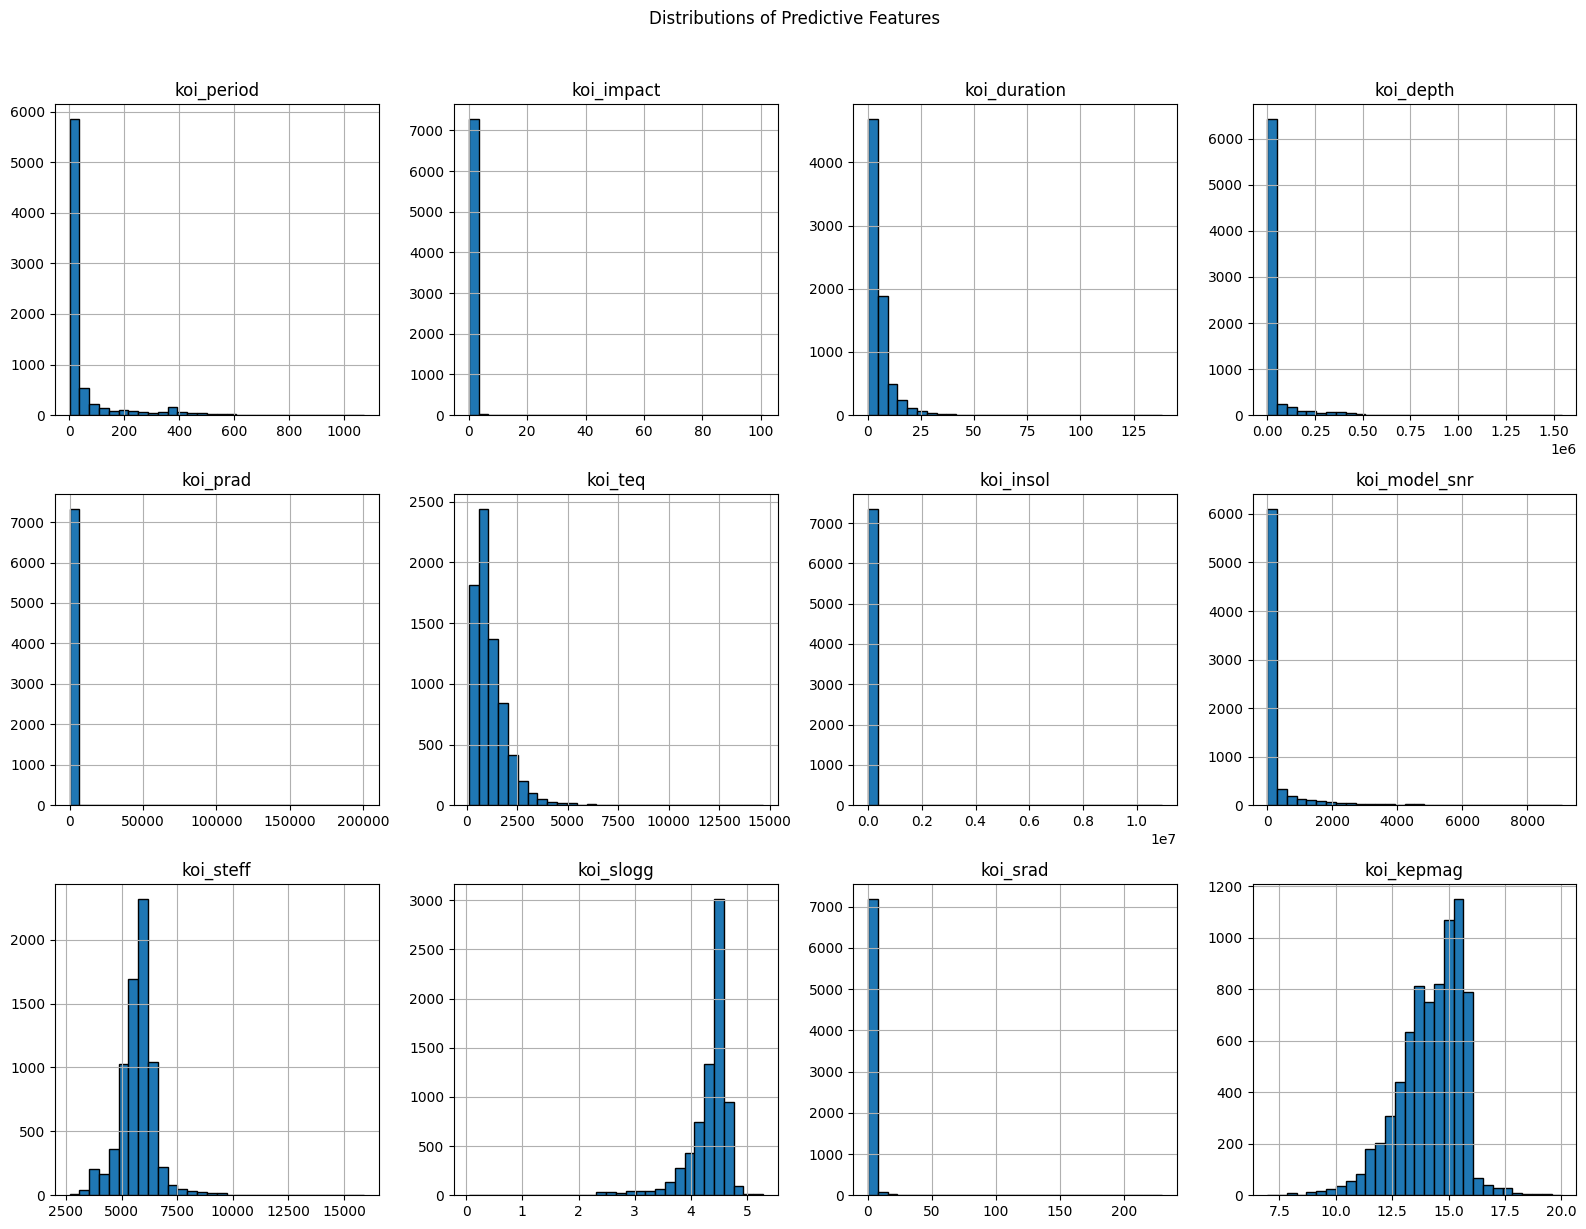

In [8]:
df[feature_columns].hist(
    bins=30,
    figsize=(16, 12),
    layout=(3, 4),
    edgecolor="black"
)

plt.suptitle("Distributions of Predictive Features", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
df[feature_columns].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T.round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
koi_period,7587.0,51.66,111.82,0.24,0.52,0.66,2.24,8.09,30.58,359.07,520.83,1071.23
koi_impact,7328.0,0.76,3.20,0.00,0.00,0.02,0.23,0.59,0.92,1.26,1.90,100.81
koi_duration,7587.0,5.71,6.83,0.10,0.85,1.29,2.48,3.84,6.27,16.41,32.16,138.54
koi_depth,7328.0,29521.85,91158.86,0.80,23.50,50.34,182.75,501.50,2318.95,221039.00,437665.60,1541400.00
koi_prad,7328.0,104.14,3180.05,0.08,0.52,0.78,1.50,2.62,24.18,95.94,399.80,200346.00
koi_teq,7328.0,1154.33,900.54,92.00,202.00,270.00,581.00,933.00,1482.00,2689.00,4308.74,14667.00
koi_insol,7368.0,9389.98,178161.42,0.02,0.39,1.28,27.22,180.46,1151.51,12566.84,84716.52,10947554.55
koi_model_snr,7328.0,318.58,880.98,0.00,5.30,7.70,15.40,30.50,114.95,1871.69,4721.84,9054.70
koi_steff,7328.0,5716.20,819.31,2661.00,3629.24,4302.00,5313.00,5774.50,6117.00,6762.00,8408.32,15896.00
koi_slogg,7328.0,4.31,0.44,0.05,2.48,3.62,4.22,4.44,4.54,4.67,4.81,5.28


### Observations

- Features differ greatly in terms of scale.
- Some features are right skewed, meaning there is a small number of observations that have huge values.
- The most wide-spread values are observed in `koi_period`, `koi_depth`, `koi_prad` and `koi_insol`.
- Mean and median values are significantly different for several features, which means the presence of skewness.

We will study the extreme observations and the distribution of features by class in the next section.

## 4. Feature Relationships

In this part, we explore the relationships of the predicting features with the classes and each other.

Firstly, we consider the distribution of the features for the true objects and false positives. Secondly, we look at the correlation of the predictors.

### 4.1 Distribution of Features in Each Class

To compare the distributions of features in both confirmed objects and false positives, we utilize boxplots.

This enables us to see which features may help distinguish these classes from one another.

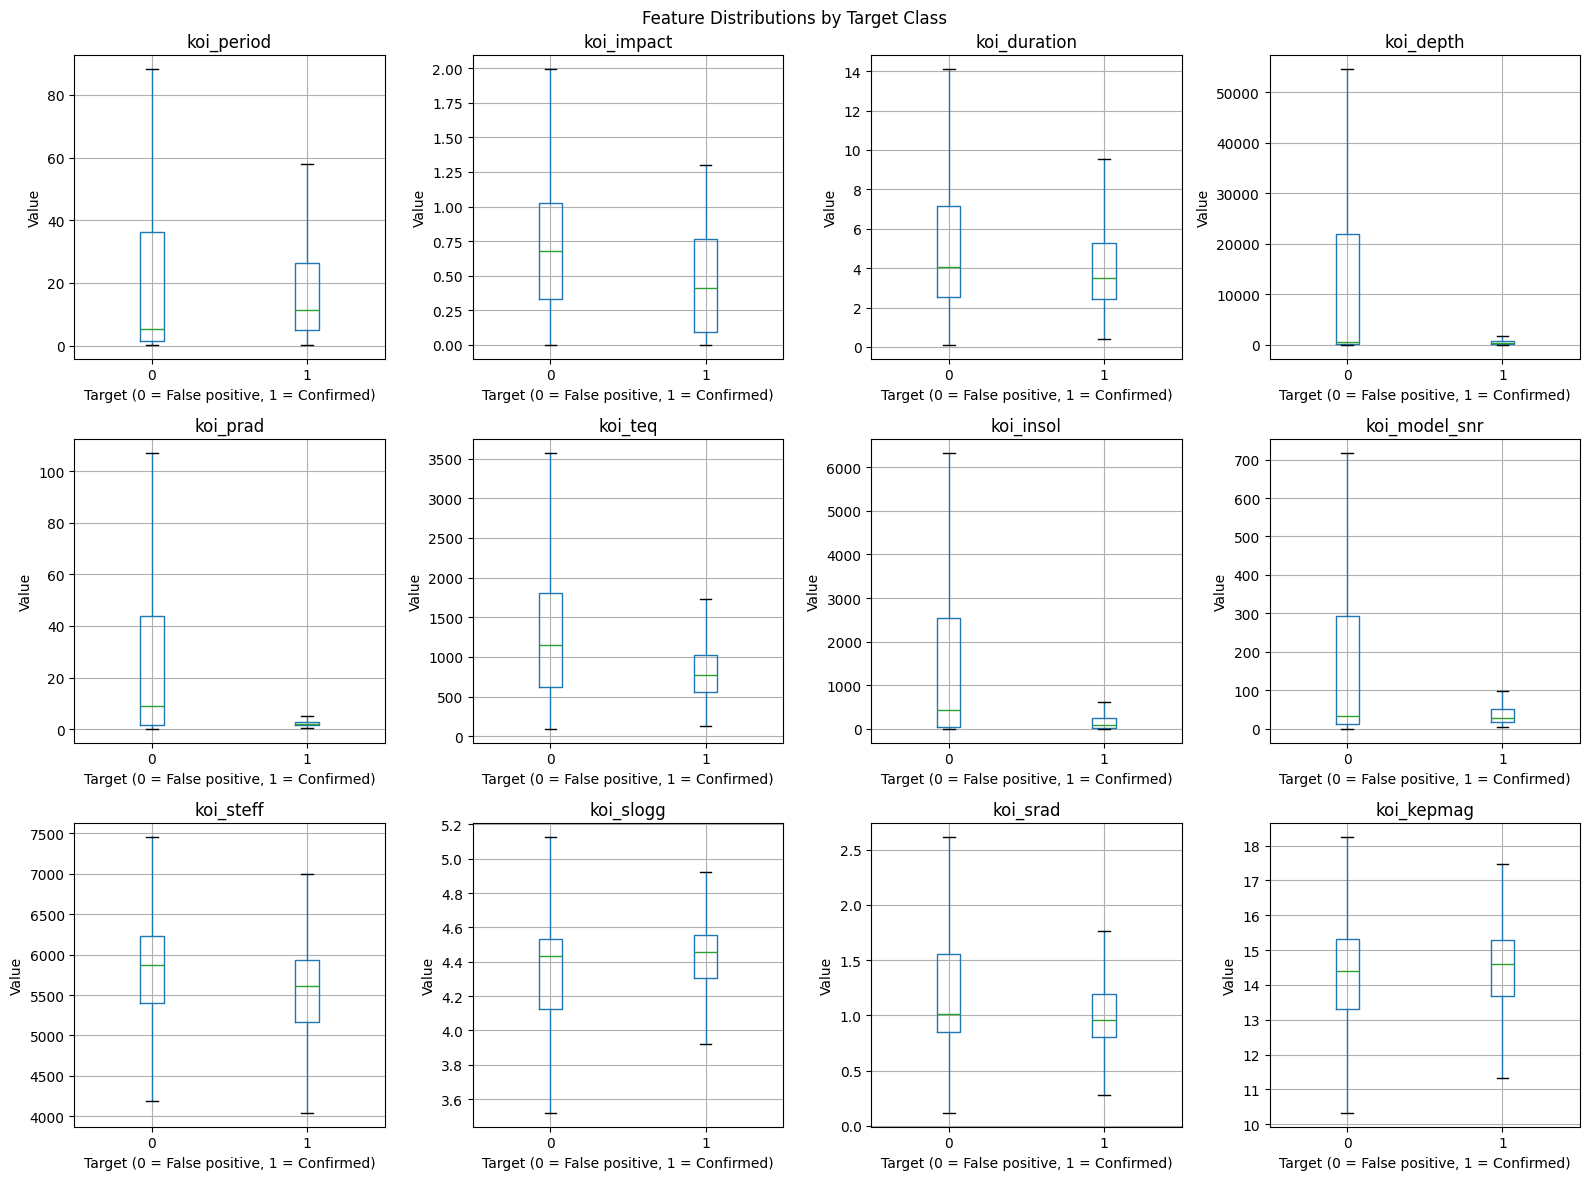

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for feature, ax in zip(feature_columns, axes.flat):
    df.boxplot(
        column=feature,
        by="target",
        ax=ax,
        showfliers=False
    )

    ax.set_title(feature)
    ax.set_xlabel("Target (0 = False positive, 1 = Confirmed)")
    ax.set_ylabel("Value")

fig.suptitle("Feature Distributions by Target Class")
plt.tight_layout()
plt.show()

### 4.2 Extreme Values

There are some features that include very high values. We determine whether or not the top 1% of these features is overrepresented in association with one of the two targets.

This gives another view of how extreme values relate to cataloged classes.

In [11]:
extreme_features = [
    "koi_impact",
    "koi_depth",
    "koi_prad",
    "koi_insol",
    "koi_srad"
]

extreme_class_results = []

for feature in extreme_features:
    n = max(1, int(np.ceil(df[feature].notna().sum() * 0.01)))

    top_observations = df.nlargest(n, feature)
    proportions = top_observations["target"].value_counts(normalize=True)

    extreme_class_results.append({
        "feature": feature,
        "observations": len(top_observations),
        "false_positive_%": proportions.get(0, 0) * 100,
        "confirmed_%": proportions.get(1, 0) * 100
    })

extreme_class_summary = (
    pd.DataFrame(extreme_class_results)
    .set_index("feature")
)

print(f"Overall false-positive percentage: {(df['target'] == 0).mean() * 100:.1f}%")

extreme_class_summary.round(1)

Overall false-positive percentage: 63.8%


,observations,false_positive_%,confirmed_%
feature,,,
koi_impact,74,100.0,0.0
koi_depth,74,100.0,0.0
koi_prad,74,100.0,0.0
koi_insol,74,100.0,0.0
koi_srad,74,98.6,1.4


The upper tails of many features have more instances of false positives than the overall number in the data set. The features that show this clearly include planetary radius, transit depth, impact parameter, and insolation.

These are not causative links but rather associations. We are keeping the data points for learning.

### 4.3 Correlations Between Features

The Spearman rank correlation coefficient is employed to determine monotonic relationships between predictors.

This technique proves valuable in our case since some variables are highly skewed and may have monotonic yet non-linear relationships.

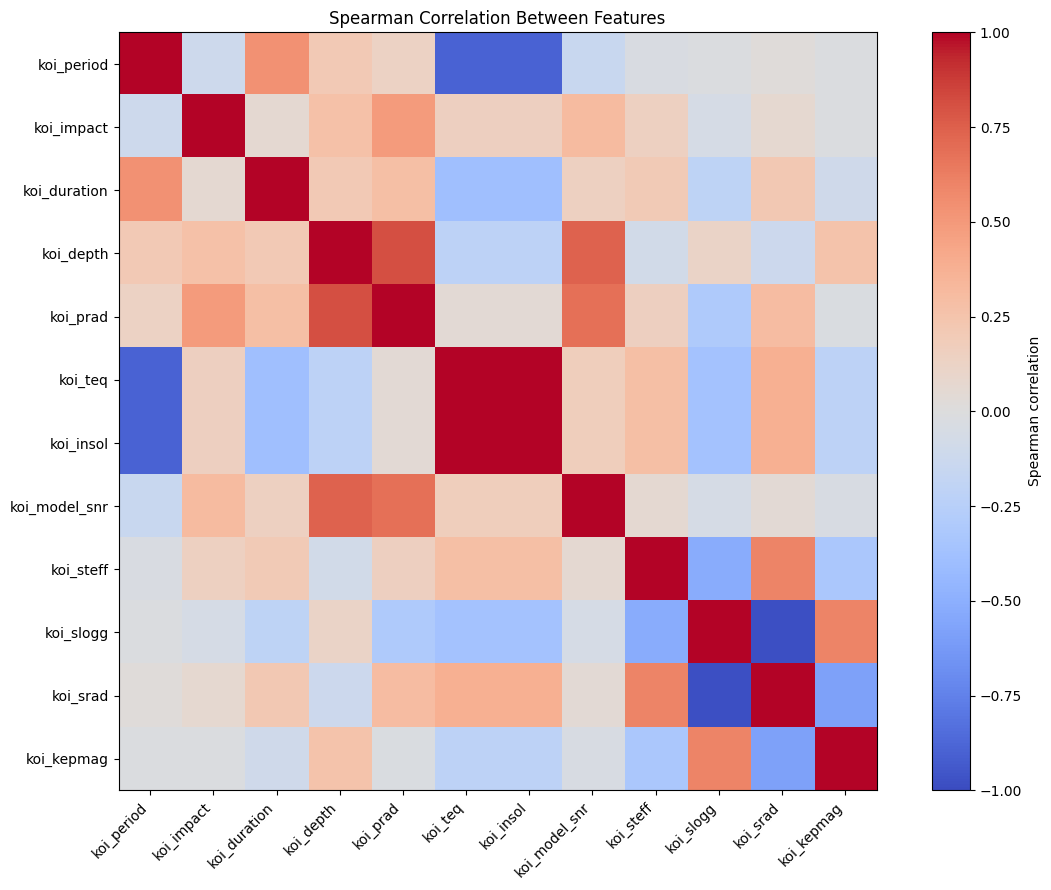

In [12]:
correlation_matrix = df[feature_columns].corr(method="spearman")

plt.figure(figsize=(12, 9))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Spearman correlation")

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(feature_columns)),
    feature_columns
)

plt.title("Spearman Correlation Between Features")

plt.tight_layout()
plt.show()

In [13]:
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

strongest_correlations = (
    upper_triangle.stack()
    .rename("spearman_correlation")
    .reset_index()
)

strongest_correlations.columns = [
    "feature_1",
    "feature_2",
    "spearman_correlation"
]

strongest_correlations["absolute_correlation"] = (
    strongest_correlations["spearman_correlation"].abs()
)

strongest_correlations.sort_values(
    "absolute_correlation",
    ascending=False
).head(10).round(3)

,feature_1,feature_2,spearman_correlation,absolute_correlation
66,koi_teq,koi_insol,1.000,1.000
118,koi_slogg,koi_srad,-0.980,0.980
5,koi_period,koi_teq,-0.893,0.893
6,koi_period,koi_insol,-0.892,0.892
40,koi_depth,koi_prad,0.809,0.809
43,koi_depth,koi_model_snr,0.739,0.739
55,koi_prad,koi_model_snr,0.683,0.683
106,koi_steff,koi_srad,0.594,0.594
119,koi_slogg,koi_kepmag,0.594,0.594
131,koi_srad,koi_kepmag,-0.581,0.581


### Observations

- There are marked differences in the distribution of several feature types between confirmed objects and false positives, including orbital period, planetary radius, equilibrium temperature, and insolation.
- Certain outliers in features can be related to false positives.
- Some predictors are correlated with each other. Equilibrium temperature and insolation are positively correlated, and there is a negative correlation between stellar surface gravity and stellar radius.
- The correlation indicates that some predictors have redundant information.

Correlated predictors will be kept. Effects of correlated predictors will be taken into account while developing models.

## 5. EDA Summary

EDA showed the following main properties of the data:

- **Class imbalance:** False positive is present in around 63.8% of all samples, while the proportion of confirmed exoplanets is 36.2%.
- **Duplicates in host stars:** The data consists of 7,587 samples from 6,641 different host stars. All duplicates in host stars should be kept within one data split to avoid leakage.
- **Missing values:** A number of numerical features have missing values. Missing value handling will take place during model preprocessing.
- **Distribution of features:** Several features have strong skewness and outliers. Outliers will not be removed initially without any reason.
- **Difference in features between two classes:** Orbital period, planetary radius, equilibrium temperature, and insolation have clear distinctions between the two target classes.
- **Feature correlation:** Some features have a high correlation level, including equilibrium temperature and insolation, as well as stellar surface gravity and stellar radius.

### Next Steps

The modeling step will involve using the group-based data split according to `kepid` column, developing pipelines of preprocessing for models, comparing multiple classification models, hyperparameter tuning, and evaluation of model performance.